# Batch 6: fair PINC vs plain NN (same design, same data, only the physics differs)
Both networks use the same design as Amr's plain NN (`scripts/plain_nn.py`):
- data: Amr's clean files (`data/clean/1dof`), every 5th row, so one step = DT = 0.02 s (= the motor delay)
- inputs: pitch theta_k, rate q_k, command now M_k, command one step ago M_(k-1)
- output: the **change** of (theta, q) over the step (small numbers, so rollout errors grow slowly)
- extra input dt (0 to 0.02 s): the network gives the change after dt, so the physics can be checked inside the step

| | plain NN | PINC |
|---|---|---|
| data loss (one step on measured flights) | yes | yes |
| start loss (dt = 0 gives no change) | yes | yes |
| physics loss (random made-up states must obey the equation) | no | yes |

Equation: theta' = q, q' = -2 xi wn q - wn^2 (theta - th0) + mu M(t - 0.02). Because the delay is exactly one step, the command acting inside step k goes from M_(k-1) to M_k (straight line).
Constants for the physics loss: simulation fit on the same train flights.

Split (Amr's `split.txt`): motors off: train impulse_1-4, test impulse_5. Hover: train doublet_1-4, test doublet_5 and doublet_6. 5 seeds per model.

## 0. Setup

In [1]:
import numpy as np, pandas as pd, torch, time, matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares
torch.set_num_threads(4)
D = '../data/clean/1dof/'
TAU = DT = 0.02          # motor delay = one step [s]
SEEDS = [0, 1, 2, 3, 4]
EPOCHS = 10000
CASES = {'motors off': dict(train=[f'impulse_{i}' for i in range(1, 5)], test=['impulse_5']),
         'hover':      dict(train=[f'doublet_{i}' for i in range(1, 5)], test=['doublet_5', 'doublet_6'])}
full = lambda n: pd.read_csv(D + n + '.csv')                       # 250 Hz, for the simulation fit
grid = lambda n: full(n).iloc[::5].reset_index(drop=True)          # 50 Hz, for the networks

## 1. Physics, written once, and the equation model

In [2]:
def accel(theta, q, M, p):
    return -2 * p['xi'] * p['wn'] * q - p['wn']**2 * (theta - p['th0']) + p['mu'] * M

def run_ivp(p, f, M=None):
    # whole-flight simulation from the first state, command delayed by TAU
    t = f.t.values; M = f.M.values if M is None else M
    rhs = lambda tt, z: [z[1], accel(z[0], z[1], np.interp(tt - TAU, t, M, left=M[0]), p)]
    return solve_ivp(rhs, (t[0], t[-1]), [f.theta[0], f.q[0]], t_eval=t, max_step=0.004).y[0]

def sim_fit(names):
    keys = ['wn', 'xi', 'mu', 'th0']; F = [full(n) for n in names]
    res = lambda v: np.concatenate([run_ivp(dict(zip(keys, v)), f) - f.theta.values for f in F])
    r = least_squares(res, [4.0, 0.2, 100, 0], bounds=([0.5, 0, 0, -0.3], [20, 2, 2000, 0.3]))
    return dict(zip(keys, r.x))

def vaf(y, yhat):
    return max(1 - np.var(y - yhat) / np.var(y), 0) * 100

## 2. The network and the step (same for PINC and plain NN)

In [3]:
def mlp(n_in, n_out, width=32, depth=3):
    layers, n = [], n_in
    for _ in range(depth):
        layers += [torch.nn.Linear(n, width), torch.nn.Tanh()]; n = width
    return torch.nn.Sequential(*layers, torch.nn.Linear(n, n_out))

col = lambda x: torch.tensor(np.asarray(x), dtype=torch.float32).reshape(-1, 1)

def pairs(names):
    # one-step examples: (theta_k, q_k, M_k, M_(k-1)) -> (theta_(k+1), q_(k+1))
    out = []
    for n in names:
        f = grid(n); th, q, M = f.theta.values, f.q.values, f.M.values
        out.append(np.column_stack([th[1:-1], q[1:-1], M[1:-1], M[:-2], th[2:], q[2:]]))
    return np.vstack(out)

def pinc_model(net, sc):
    # sc = scaling numbers from the train data; returns (theta, q) after dt
    def step(th, q, M, Mp, dt):
        x = torch.cat([(th - sc['m'][0]) / sc['s'][0], (q - sc['m'][1]) / sc['s'][1],
                       (M - sc['m'][2]) / sc['s'][2], (Mp - sc['m'][3]) / sc['s'][3], dt / DT], 1)
        o = net(x)
        return th + sc['d'][0] * o[:, :1], q + sc['d'][1] * o[:, 1:2]     # state + change
    return step

## 3. Training function (PINC when w_phys = 1, plain NN when w_phys = 0)

In [4]:
def train_pinc(names, p, seed=0, epochs=EPOCHS, lr=1e-3, w_phys=1.0, n_col=2000):
    # data
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    A = pairs(names)
    sc = dict(m=A[:, :4].mean(0), s=A[:, :4].std(0) + 1e-6, d=(A[:, 4:6] - A[:, :2]).std(0))
    th0, q0, M0, Mp0, th1, q1 = [col(A[:, i]) for i in range(6)]
    lo, hi = A[:, :4].min(0), A[:, :4].max(0); pad = 0.2 * (hi - lo)       # made-up states: train range + 20 %
    # network
    net = mlp(5, 2); step = pinc_model(net, sc)
    # optimizer
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs, eta_min=lr / 20)
    # loop
    hist = []
    for e in range(epochs):
        a, b = step(th0, q0, M0, Mp0, torch.full_like(th0, DT))
        data = (((a - th1) / sc['d'][0])**2).mean() + (((b - q1) / sc['d'][1])**2).mean()
        a, b = step(th0, q0, M0, Mp0, torch.zeros_like(th0))
        start = (((a - th0) / sc['d'][0])**2).mean() + (((b - q0) / sc['d'][1])**2).mean()
        physics = torch.tensor(0.0)
        if w_phys > 0:
            z = [col(rng.uniform(lo[i] - pad[i], hi[i] + pad[i], n_col)) for i in range(4)]
            dt = col(rng.uniform(0, DT, n_col)).requires_grad_(True)
            a, b = step(*z, dt)
            da = torch.autograd.grad(a, dt, torch.ones_like(a), create_graph=True)[0]
            db = torch.autograd.grad(b, dt, torch.ones_like(b), create_graph=True)[0]
            Mt = z[3] + (dt / DT) * (z[2] - z[3])                       # delayed command inside the step
            physics = (((da - b) * DT / sc['d'][0])**2).mean() + (((db - accel(a, b, Mt, p)) * DT / sc['d'][1])**2).mean()
        loss = data + start + w_phys * physics
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        if e % 1000 == 0 or e == epochs - 1:
            hist.append((e, data.item(), start.item(), physics.item()))
    return dict(step=step, history=pd.DataFrame(hist, columns=['epoch', 'data', 'start', 'physics']))

## 4. Runner: whole-flight rollout (each output is the next input)

In [5]:
def run_open(step, f, M=None):
    th, q = f.theta.values, f.q.values; M = f.M.values if M is None else M
    a, b = th[1], q[1]; out = [th[0], a]
    with torch.no_grad():
        for k in range(1, len(f) - 1):
            a, b = step(col([a]), col([b]), col([M[k]]), col([M[k - 1]]), col([DT])); a, b = a.item(), b.item()
            out.append(a)
    return np.array(out)

## 5. Train and test both cases

In [6]:
res, P, runs = [], {}, {}
for case, cfg in CASES.items():
    t0 = time.time(); P[case] = sim_fit(cfg['train'])
    print(case, 'sim-fit constants', {k: round(v, 4) for k, v in P[case].items()}, f'({time.time() - t0:.0f} s)')
    runs[case] = {'PINC': [], 'plain NN': []}
    for s in SEEDS:
        for label, wp in [('PINC', 1.0), ('plain NN', 0.0)]:
            t0 = time.time(); r = train_pinc(cfg['train'], P[case], seed=s, w_phys=wp)
            runs[case][label].append(r); print(' ', label, 'seed', s, f'{time.time() - t0:.0f} s', r['history'].iloc[-1][['data', 'start', 'physics']].to_dict())
    for n in cfg['test']:
        f = grid(n); y = f.theta.values
        res.append(dict(case=case, test=n, model='Equation (sim-fit constants)', VAF=vaf(y, run_ivp(P[case], f)), std=0.0))
        for label in ['PINC', 'plain NN']:
            v = [vaf(y, run_open(r['step'], f)) for r in runs[case][label]]
            res.append(dict(case=case, test=n, model=label, VAF=np.mean(v), std=np.std(v)))
T = pd.DataFrame(res).round(2)
amr = pd.read_csv('../results/plain_nn_summary.csv')
T['Amr plain NN (impulse-trained)'] = T.test.map(dict(zip(amr.test_flight, amr.VAF_pitch_mean.round(2))))
T.to_csv('../results/batch6_fair_pinc_vs_plain_nn.csv', index=False)
T

motors off sim-fit constants {'wn': np.float64(4.0725), 'xi': np.float64(0.2126), 'mu': np.float64(77.9066), 'th0': np.float64(0.0006)} (17 s)


  PINC seed 0 52 s {'data': 0.02353358082473278, 'start': 0.0034298296086490154, 'physics': 0.0039480384439229965}


  plain NN seed 0 21 s {'data': 0.007349388673901558, 'start': 5.2252464229241014e-05, 'physics': 0.0}


  PINC seed 1 50 s {'data': 0.022084228694438934, 'start': 0.002554160077124834, 'physics': 0.0034166756086051464}


  plain NN seed 1 21 s {'data': 0.00726288603618741, 'start': 3.1148712878348306e-05, 'physics': 0.0}


  PINC seed 2 50 s {'data': 0.0223462525755167, 'start': 0.0030722408555448055, 'physics': 0.00367693486623466}


... (13 outputs left out)

  plain NN seed 3 16 s {'data': 0.018165934830904007, 'start': 6.34992538834922e-05, 'physics': 0.0}


  PINC seed 4 45 s {'data': 0.04703771322965622, 'start': 0.004966044798493385, 'physics': 0.011853000149130821}


  plain NN seed 4 16 s {'data': 0.021508848294615746, 'start': 7.733947859378532e-05, 'physics': 0.0}


,case,test,model,VAF,std,Amr plain NN (impulse-trained)
0,motors off,impulse_5,Equation (sim-fit constants),96.86,0.00,99.79
1,motors off,impulse_5,PINC,99.23,0.07,99.79
2,motors off,impulse_5,plain NN,99.78,0.02,99.79
3,hover,doublet_5,Equation (sim-fit constants),98.64,0.00,89.77
4,hover,doublet_5,PINC,58.09,4.62,89.77
5,hover,doublet_5,plain NN,12.59,17.62,89.77
6,hover,doublet_6,Equation (sim-fit constants),85.82,0.00,79.87
7,hover,doublet_6,PINC,90.80,3.24,79.87
8,hover,doublet_6,plain NN,9.50,15.04,79.87


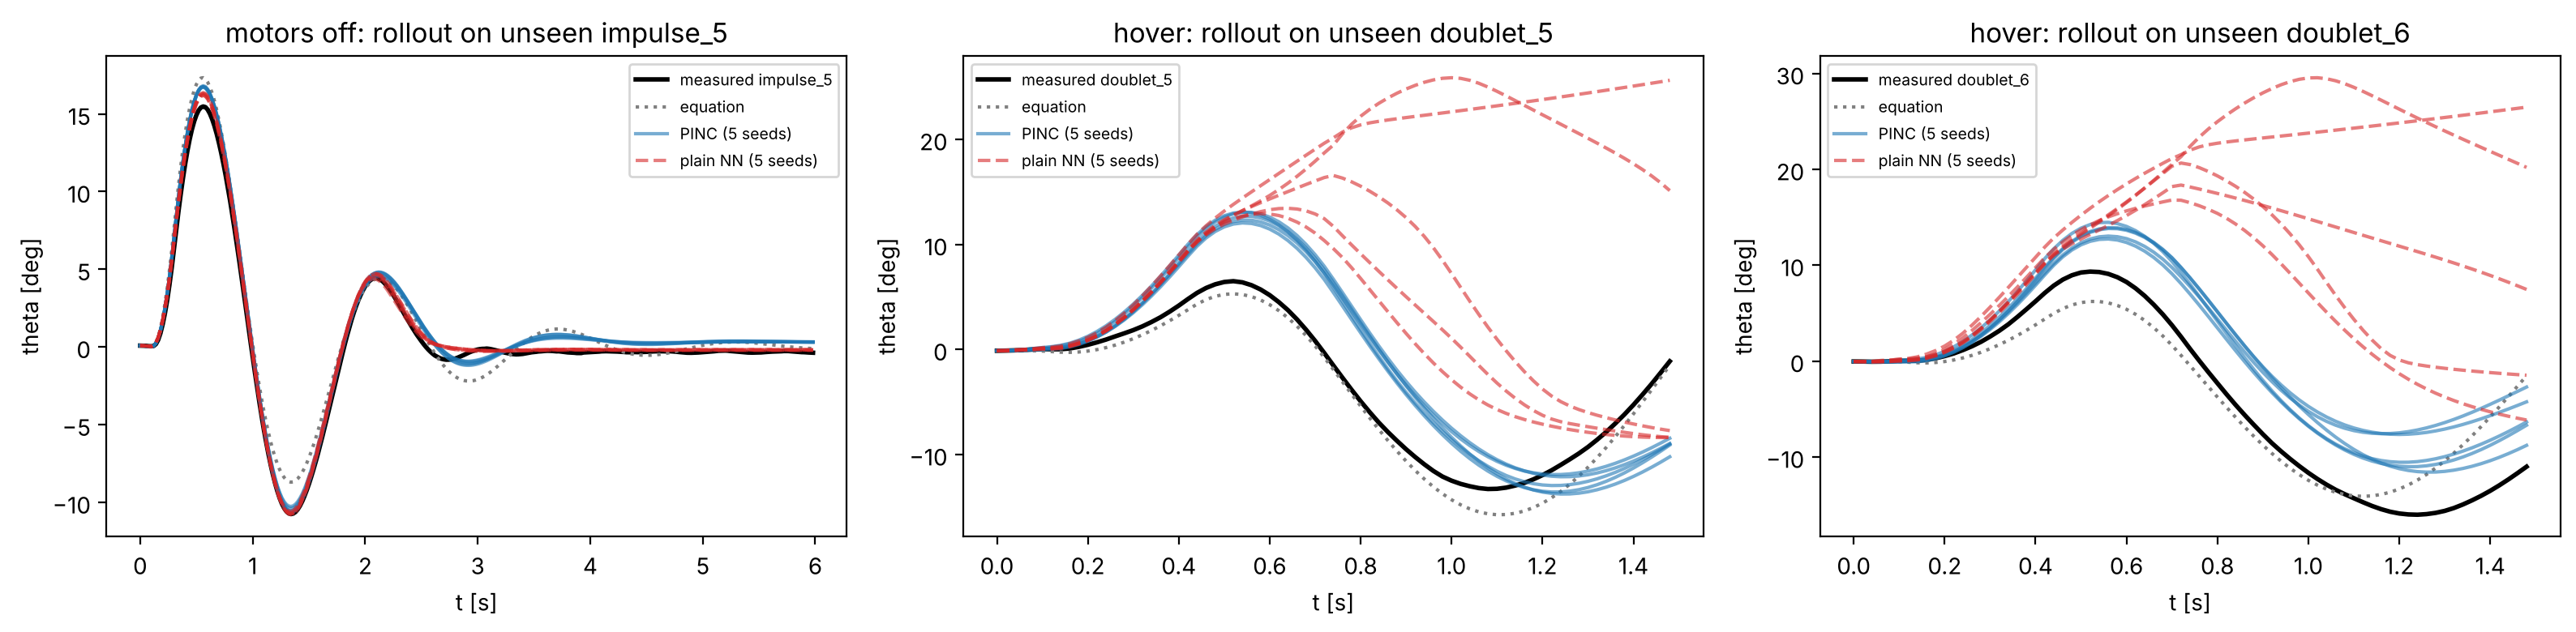

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, (case, n) in zip(ax, [('motors off', 'impulse_5'), ('hover', 'doublet_5'), ('hover', 'doublet_6')]):
    f = grid(n)
    a.plot(f.t, np.degrees(f.theta), 'k', lw=2, label='measured ' + n)
    a.plot(f.t, np.degrees(run_ivp(P[case], f)), ':', color='gray', label='equation')
    for label, color, ls in [('PINC', 'C0', '-'), ('plain NN', 'C3', '--')]:
        for i, r in enumerate(runs[case][label]):
            a.plot(f.t, np.degrees(run_open(r['step'], f)), ls, color=color, alpha=0.6, label=label + ' (5 seeds)' if i == 0 else None)
    a.set(title=f'{case}: rollout on unseen {n}', xlabel='t [s]', ylabel='theta [deg]'); a.legend(fontsize=7)
plt.tight_layout(); plt.savefig('../figures/batch6_fair_rollouts.png', dpi=120, bbox_inches='tight'); plt.show()

## 6. New inputs never seen in training (hover)
Same test as Batch 3: the doublet_6 command made 1.5 times bigger, and a constant push for 1 s. No measured flight exists, so the reference is the equation.

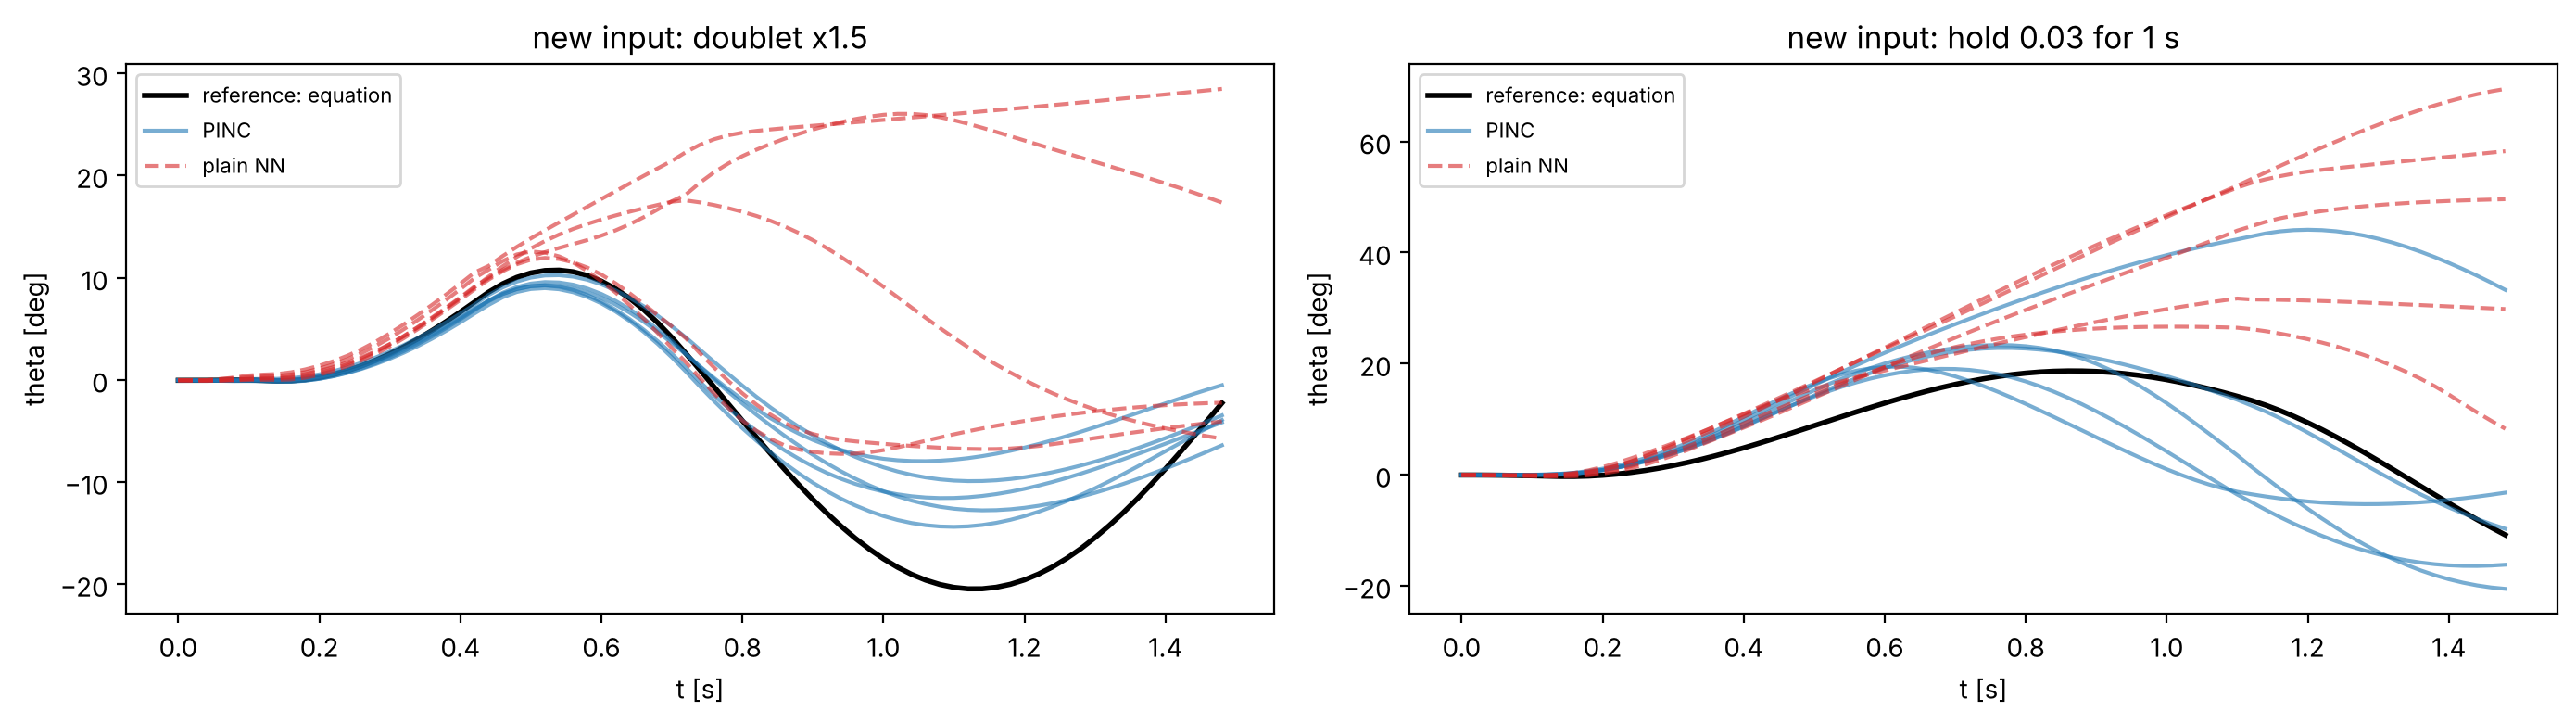

,input,model,VAF,std
0,doublet x1.5,PINC,85.55,6.30
1,doublet x1.5,plain NN,29.85,35.52
2,hold 0.03 for 1 s,PINC,17.91,35.58
3,hold 0.03 for 1 s,plain NN,8.64,17.29


In [8]:
case = 'hover'; f = grid('doublet_6'); M = f.M.values
new = {'doublet x1.5': 1.5 * M, 'hold 0.03 for 1 s': np.where((f.t > 0.1) & (f.t < 1.1), 0.03, 0.0)}
rows2 = []
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for a, (name, Mn) in zip(ax, new.items()):
    ref = run_ivp(P[case], f, Mn)
    a.plot(f.t, np.degrees(ref), 'k', lw=2, label='reference: equation')
    for label, color, ls in [('PINC', 'C0', '-'), ('plain NN', 'C3', '--')]:
        ys = [run_open(r['step'], f, Mn) for r in runs[case][label]]
        v = [vaf(ref, y) for y in ys]; rows2.append(dict(input=name, model=label, VAF=np.mean(v), std=np.std(v)))
        for i, y in enumerate(ys): a.plot(f.t, np.degrees(y), ls, color=color, alpha=0.6, label=label if i == 0 else None)
    a.set(title='new input: ' + name, xlabel='t [s]', ylabel='theta [deg]'); a.legend(fontsize=8)
plt.tight_layout(); plt.savefig('../figures/batch6_new_inputs.png', dpi=120, bbox_inches='tight'); plt.show()
T2 = pd.DataFrame(rows2).round(2); T2.to_csv('../results/batch6_new_inputs.csv', index=False); T2

## 7. What this shows
- Same design and data for both networks, so any gap is from the physics loss alone.
- Measured test flights: how well each copies real flights it never saw.
- New inputs: how well each behaves where there is no data, which is what a controller needs.